In [1]:
# Reset all variables and imports for memory management
%reset -f

# Enable automatic module reloading
%load_ext autoreload
%autoreload 2

import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

import sys
import os
import random
import numpy as np
import json

import torch
import torchvision

from segment_anything import sam_model_registry

# Ensure that the project root is in the sys.path
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '..')))

from utils.utils_setup import choose_device

device = torch.device(choose_device())
print(torch.cuda.get_device_name(device))

# Load sam, resnet and imagenet_labels
sam = sam_model_registry["vit_h"](checkpoint="../sam_models/sam_vit_h_4b8939.pth").to(device)

resnet = torchvision.models.resnet50(weights="ResNet50_Weights.IMAGENET1K_V2")
resnet.eval().to(device);

with open("../imagenet_class_index.json") as f:
    imagenet_labels = list(json.load(f).values())

# fix seed for reproducibility
seed = 123
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
torch.cuda.manual_seed(seed)
torch.cuda.manual_seed_all(seed) # multi-GPU

NVIDIA A100-PCIE-40GB


## PASCAL Dataset

In [18]:
from torch.utils.data import ConcatDataset
from utils.utils import SquareCropAndResize
from PIL import Image

square_crop_transform = SquareCropAndResize(size=None, interpolation=Image.NEAREST)

pascal_ds_val = torchvision.datasets.VOCSegmentation(
    root="../data/VOCSegmentation",
    year="2012",
    image_set="val",
    download=True,
    transform=square_crop_transform,
    target_transform=square_crop_transform,
)

pascal_ds_train = torchvision.datasets.VOCSegmentation(
    root="../data/VOCSegmentation",
    year="2012",
    image_set="train",
    download=True,
    transform=square_crop_transform,
    target_transform=square_crop_transform,
)

# Combine training and validation dataset
pascal_ds = ConcatDataset([pascal_ds_val, pascal_ds_train])

Using downloaded and verified file: ../data/VOCSegmentation/VOCtrainval_11-May-2012.tar
Extracting ../data/VOCSegmentation/VOCtrainval_11-May-2012.tar to ../data/VOCSegmentation
Using downloaded and verified file: ../data/VOCSegmentation/VOCtrainval_11-May-2012.tar
Extracting ../data/VOCSegmentation/VOCtrainval_11-May-2012.tar to ../data/VOCSegmentation


In [3]:
pascal_labels = {
    1: "aeroplane",
    2: "bicycle",
    3: "bird",
    4: "boat",
    5: "bottle",
    6: "bus",
    7: "car",
    8: "cat",
    9: "chair",
    10: "cow",
    11: "diningtable",
    12: "dog",
    13: "horse",
    14: "motorbike",
    15: "person",
    16: "potted plant",
    17: "sheep",
    18: "sofa",
    19: "train",
    20: "tv/monitor",
}

exclude_classes = [
    "person",
    "tv/monitor",
    "sofa",
    "potted plant",
    "diningtable",
    "chair",
    "bottle",
]

### Create pandas datadrame from torch dataset

Number of images: 2913


<Axes: title={'center': 'Pascal VOC 2012 - labels distribution'}, xlabel='label_names'>

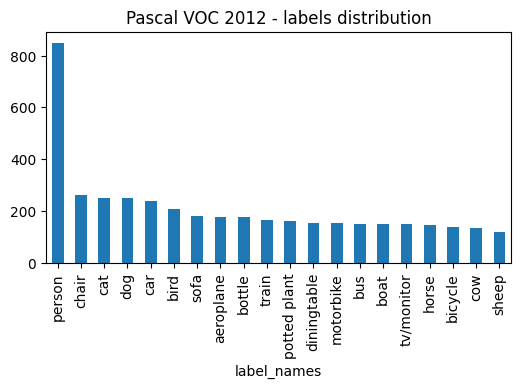

In [4]:
import pandas as pd
from utils.utils_data import DatasetToDataFrameConverter

# Convert to df_sample
converter = DatasetToDataFrameConverter(pascal_ds, pascal_labels)
pascal_df = converter.convert()

print(f"Number of images: {len(pascal_df)}")

pascal_df["label_names"].explode().value_counts().plot(
    kind="bar", figsize=(6, 3), title="Pascal VOC 2012 - labels distribution"
)

Number of images: 1509


<Axes: title={'center': 'Pascal VOC 2012 - labels distribution'}, xlabel='label_names'>

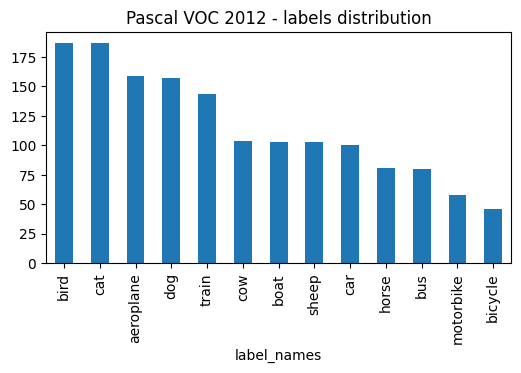

In [5]:
pascal_df = pascal_df[pascal_df["label_count"] == 1].copy()

pascal_df = pascal_df[
    ~pascal_df["label_names"].apply(lambda x: any(cls in x for cls in exclude_classes))
].copy()

print(f"Number of images: {len(pascal_df)}")

pascal_df["label_names"].explode().value_counts().plot(
    kind="bar", figsize=(6, 3), title="Pascal VOC 2012 - labels distribution"
)

### Filter ds the same way as df was filtered

In [20]:
from torch.utils.data import Subset
from utils.utils_data import filter_dataset_by_classes

# Apply the filtering function
filtered_indices = filter_dataset_by_classes(pascal_ds, exclude_classes, pascal_labels)

# Create a filtered dataset with only the selected indices
pascal_ds_filtered = Subset(pascal_ds, filtered_indices)

print("Filtered dataset size:", len(pascal_ds_filtered))

Filtered dataset size: 1509


### Define XAI methods

In [7]:
from utils.xai_methods import LRP, GradCAMHeatmap

from zennit.composites import (
    EpsilonPlus,
    EpsilonPlusFlat,
    ExcitationBackprop,
    EpsilonGammaBox,
)
from zennit.canonizers import SequentialMergeBatchNorm
# from zennit.torchvision import ResNetCanonizer

xai_methods = (
    (
        "GradCAM",
        GradCAMHeatmap(resnet, resnet.layer4),
    ),
    (
        "EP",
        LRP(
            model=resnet,
            composite=EpsilonPlus(canonizers=[SequentialMergeBatchNorm()]),
            LRP_target_layer=None,
        ),
    ),    
    (
        "EP 1.0.conv2",
        LRP(
            model=resnet,
            composite=EpsilonPlus(canonizers=[SequentialMergeBatchNorm()]),
            LRP_target_layer="layer1.0.conv2",
        ),
    ),
    (
        "EP 2.0.conv2",
        LRP(
            resnet,
            composite=EpsilonPlus(canonizers=[SequentialMergeBatchNorm()]),
            LRP_target_layer="layer2.0.conv2",
        ),
    ),
    (
        "EP 3.0.conv2",
        LRP(
            resnet,
            composite=EpsilonPlus(canonizers=[SequentialMergeBatchNorm()]),
            LRP_target_layer="layer3.0.conv2",
        ),
    ),
    (
        "GB",
        LRP(
            resnet,
            composite=EpsilonGammaBox(
                high=3, low=-3, canonizers=[SequentialMergeBatchNorm()]
            ),
            LRP_target_layer=None,
        ),
    ),

    (
        "GB 1.0.conv2",
        LRP(
            resnet,
            composite=EpsilonGammaBox(
                high=3, low=-3, canonizers=[SequentialMergeBatchNorm()]
            ),
            LRP_target_layer="layer1.0.conv2",
        ),
    ),
    (
        "GB 2.0.conv2",
        LRP(
            resnet,
            composite=EpsilonGammaBox(
                high=3, low=-3, canonizers=[SequentialMergeBatchNorm()]
            ),
            LRP_target_layer="layer2.0.conv2",
        ),
    ),
    (
        "GB 3.0.conv2",
        LRP(
            resnet,
            composite=EpsilonGammaBox(
                high=3, low=-3, canonizers=[SequentialMergeBatchNorm()]
            ),
            LRP_target_layer="layer3.0.conv2",
        ),
    ),
)

/home/dai/araystds/miniconda3/envs/lrp/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Define evaluation metrics

In [8]:
from utils.metrics import (
    IoU,
    Precision,
    Recall,
    F1Score,
    DiceCoefficient,
    BoundaryIoU,
    AverageSurfaceDistance,
    AverageSymmetricSurfaceDistance,
    HausdorffDistance,
    NormalizedSurfaceDistance
)

dilation_radius = 3
threshold = 0.3 # only for heatmaps


metrics = {
    'iou': IoU(threshold=threshold),
    'precision': Precision(threshold=threshold),
    'recall': Recall(threshold=threshold),
    'f1': F1Score(threshold=threshold),
    'dice': DiceCoefficient(threshold=threshold),
    'biou': BoundaryIoU(dilation_radius=dilation_radius, threshold=threshold),
    'asd': AverageSurfaceDistance(threshold=threshold),
    'assd': AverageSymmetricSurfaceDistance(dilation_radius=dilation_radius, threshold=threshold),
    'hd': HausdorffDistance(threshold=threshold),
    'nsd': NormalizedSurfaceDistance(threshold=threshold),
}

### Run on N samples and print results

#### Create ds_sample and df_sample

In [43]:
import random

N = 5

# Generate ds_sample
image_indices = random.sample(range(len(pascal_ds_filtered)), N)
ds_sample = Subset(pascal_ds_filtered, image_indices)

# Convert to df_sample
converter = DatasetToDataFrameConverter(ds_sample, pascal_labels)
df_sample = converter.convert()

# Update the 'dataset_idx' column to use image_indices (original_ds_idx)
df_sample['dataset_idx'] = image_indices

df_sample

,dataset_idx,labels,label_count,label_names
0,25,[13],1,[horse]
1,815,[1],1,[aeroplane]
2,1323,[3],1,[bird]
3,1050,[6],1,[bus]
4,889,[12],1,[dog]


#### Visualization

 40%|████      | 2/5 [01:52<02:47, 55.98s/it]/home/dai/araystds/miniconda3/envs/lrp/lib/python3.12/site-packages/numpy/core/fromnumeric.py:3504: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/dai/araystds/miniconda3/envs/lrp/lib/python3.12/site-packages/numpy/core/_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
100%|██████████| 5/5 [04:23<00:00, 52.63s/it]


,dataset_idx,label_names
0,25,[horse]
1,815,[aeroplane]
2,1323,[bird]
3,1050,[bus]
4,889,[dog]


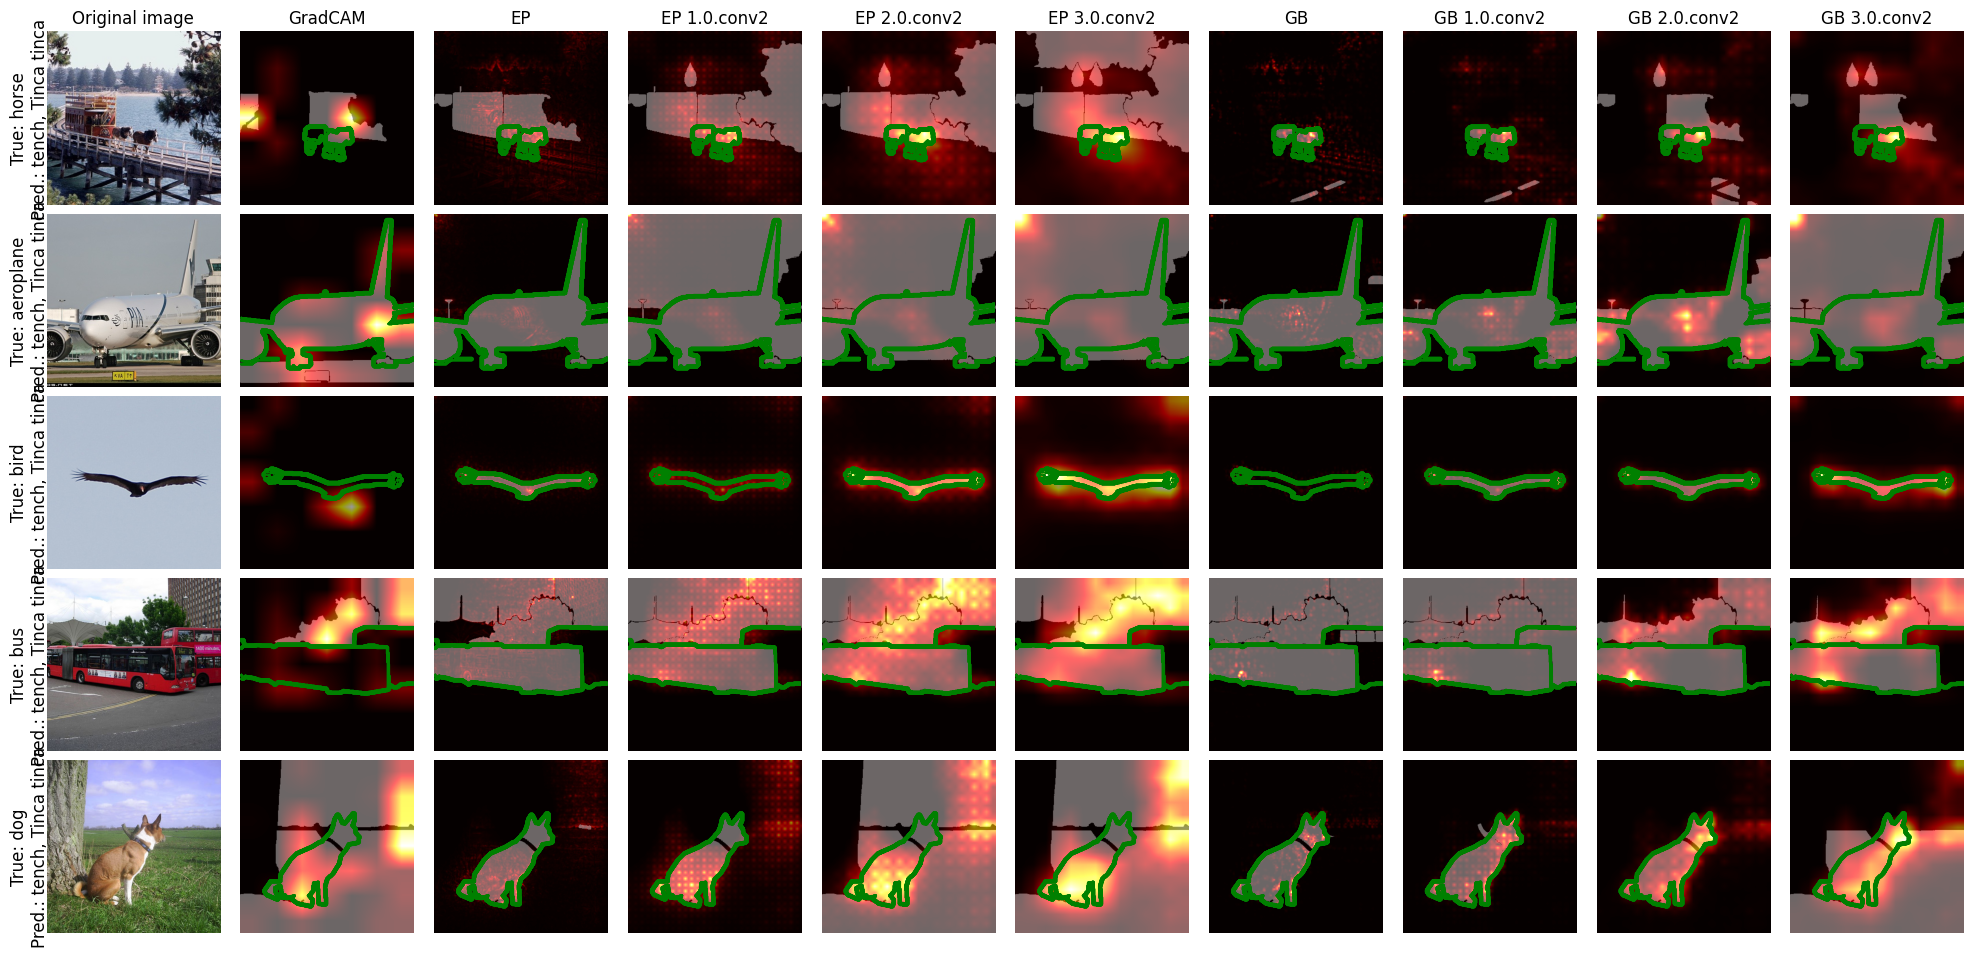

In [44]:
import matplotlib.pyplot as plt
import tqdm
from utils.utils_ImageProcessor import ImageProcessor

# Initialize the ImageProcessor
image_processor = ImageProcessor(ds_sample, resnet, sam, imagenet_labels, xai_methods, metrics, pascal_labels)

# Create subplots based on the number of samples and XAI methods
fig, axes = plt.subplots(
    nrows=len(df_sample),
    ncols=len(xai_methods) + 1,  # +1 for the original image
    figsize=((len(xai_methods) + 1) * 2, 2 * len(df_sample)),
)

# Turn off axes for all subplots
for ax in axes.flatten():
    ax.axis("off")

# Loop over the samples and process each image
for i, row in enumerate(tqdm.tqdm(df_sample.itertuples(), total=len(df_sample))):
    # Process each image and get the visualization data
    visualization_data = image_processor.process_image(i, visualization=True)

    # Display the original image
    if i == 0:
        axes[i, 0].title.set_text("Original image")
    axes[i, 0].imshow(visualization_data[0]['img'])  # Take img from the first XAI method's data

    # Add vertical title on the left with true and predicted labels
    axes[i, 0].text(
        -0.1, 0.5,
        f"True: {visualization_data[0]['true_label']}\nPred.: {visualization_data[0]['pred_label']}",
        size=12,
        ha="center",
        va="center",
        rotation=90,
        transform=axes[i, 0].transAxes,
    )

    # Loop over the XAI methods and display heatmap + mask for each
    for j, vis_data in enumerate(visualization_data):
        if i == 0:
            axes[i, j + 1].title.set_text(vis_data['xai_method'])  # Add XAI method title

        # Display the combined mask and heatmap on top of it
        axes[i, j + 1].imshow(vis_data['combined_mask'], cmap="gray")
        axes[i, j + 1].imshow(vis_data['heatmap'], cmap="hot", alpha=0.6)
        axes[i, j + 1].contour(vis_data['ground_truth_mask'], colors='g')

# Adjust the layout to fit the plots
plt.tight_layout()

# Remove margins between subplots
plt.subplots_adjust(wspace=0, hspace=0.05)

# Display the sample DataFrame
df_sample.loc[:, ["dataset_idx", "label_names"]]

#### Evaluation

In [45]:
from utils.utils_ImageProcessor import ImageProcessor
import tqdm

image_processor = ImageProcessor(ds_sample, resnet, sam, imagenet_labels, xai_methods, metrics, pascal_labels)

# Loop over the indices and process each image
for idx in tqdm.tqdm(range(len(ds_sample))):
    image_processor.process_image(idx)

# Get the final results after processing all images
final_results_df = image_processor.get_final_results()

pd.DataFrame(final_results_df)


  0%|          | 0/5 [00:00<?, ?it/s]

 40%|████      | 2/5 [01:50<02:45, 55.25s/it]/home/dai/araystds/miniconda3/envs/lrp/lib/python3.12/site-packages/numpy/core/fromnumeric.py:3504: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/dai/araystds/miniconda3/envs/lrp/lib/python3.12/site-packages/numpy/core/_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
100%|██████████| 5/5 [04:20<00:00, 52.09s/it]


,dataset_idx,xai_method,true_label,pred_label,iou,precision,recall,f1,dice,biou,asd,assd,hd,nsd
0,0,GradCAM,horse,"tench, Tinca tinca",0.099772,0.127094,0.316988,0.181441,0.000820,0.008442,245.368206,36.750991,134.718224,0.076185
1,0,EP,horse,"tench, Tinca tinca",0.114663,0.127882,0.525894,0.205736,0.000887,0.009392,236.690000,35.940647,133.360414,0.065051
2,0,EP 1.0.conv2,horse,"tench, Tinca tinca",0.063668,0.067368,0.536903,0.119714,0.000495,0.007109,258.746439,57.324534,194.620143,0.085387
3,0,EP 2.0.conv2,horse,"tench, Tinca tinca",0.063546,0.067231,0.536903,0.119498,0.000494,0.007058,258.801506,57.894173,194.620143,0.086012
4,0,EP 3.0.conv2,horse,"tench, Tinca tinca",0.043535,0.045233,0.536903,0.083437,0.000339,0.005637,242.446867,71.560531,204.286563,0.116054
5,0,GB,horse,"tench, Tinca tinca",0.376351,0.710969,0.444333,0.546882,0.002994,0.020402,274.588077,22.696720,82.036577,0.040401
6,0,GB 1.0.conv2,horse,"tench, Tinca tinca",0.376351,0.710969,0.444333,0.546882,0.002994,0.020402,274.588077,22.696720,82.036577,0.040401
7,0,GB 2.0.conv2,horse,"tench, Tinca tinca",0.149758,0.175630,0.504128,0.260504,0.001160,0.008251,258.662178,44.452180,134.316790,0.068755
8,0,GB 3.0.conv2,horse,"tench, Tinca tinca",0.101626,0.130034,0.317488,0.184501,0.000835,0.007444,245.257699,43.495603,133.360414,0.075099
9,1,GradCAM,aeroplane,"tench, Tinca tinca",0.662124,0.731967,0.874042,0.796720,0.005062,0.045514,200.382032,6.468632,65.069194,0.009074


#### Save pandas DataFrame as csv file (optional)

In [23]:
from utils.utils_data import save_dataframe_to_csv

# Specify the file_name and folder where you want to save the CSV
file_name = "pipeline2_n_sample_evaluation"
folder_path = "../results" 

try:
    save_dataframe_to_csv(final_results_df, file_name, folder_path)
except FileNotFoundError as e:
    print(e)

DataFrame saved as CSV at: ../results/pipeline2_n_sample_evaluation_2024-10-14_12-18-17.csv


### Run on whole dataset

In [ ]:
image_processor = ImageProcessor(pascal_ds_filtered, resnet, sam, imagenet_labels, xai_methods, pascal_labels)

for idx in tqdm.tqdm(range(len(pascal_ds_filtered))):
    image_processor.process_image(idx)
    
final_results_df = image_processor.get_final_results()

In [ ]:
file_name = "pipeline2_evaluation"
folder_path = "../results" 

try:
    save_dataframe_to_csv(final_results_df, file_name, folder_path)
except FileNotFoundError as e:
    print(e)